In [1]:
import numpy as np
import math

from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize

from problem_model import TorqueDistributionProblem, model
from classes import CarParams, Reference, WeelTork, Vehicle_state
from vehicle import generate_torque_reference, vehicle_dynamics
from grid import  dijkstra, dijkstra_reverso, plot_trajectory, build_cost_map

import matplotlib.pyplot as plt


A função abaixo plota a curva de pareto dada a solução

In [2]:
def plot_pareto(F):
    plt.figure(figsize=(9, 6))

    plt.scatter(
        F[:, 0],
        F[:, 1],
        c='blue',
        s=35,
        alpha=0.8
    )

    plt.xlabel('Erro de momento de guinada normalizado')
    plt.ylabel('Perdas energéticas normalizadas')

    plt.title('Fronteira de Pareto - NSGA-II')

    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

## Definição dos parametros


Essa seção define os parametros fisicos do carrinho

In [ ]:
# Definindo parametros do veículo
car_params = CarParams(
    wheel_radius=0.10,      # m
    gear_ratio=1.0,         # -
    track_width=0.40,       # m

    T_min=0,              # N.m
    T_max=5,              # N.m

    loss_coeff=0.5,
    Ploss_scale=1000.0,     # W

    mass=12.0,              # kg
    yaw_inertia=0.80        # kg.m²
)


In [4]:
race = [
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 1, 1, 1, 1, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100, 100, 1, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 1, 1, 1000, 1, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100, 100, 100],
    [100, 100, 100, 1, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100, 100],
    [100, 100, 1, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100],
    [100, 1, 100, 100, 100, 1, 1, 1, 100, 100, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100],
    [100, 1, 100, 100, 100, 1, 100, 100, 1, 100, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100],
    [100, 1, 100, 100, 100, 1, 1, 100, 100, 1, 100, 100, 100, 100, 100, 100, 1, 100, 100, 100],
    [100, 100, 1, 100, 100, 100, 100, 1, 100, 1, 1, 100, 100, 100, 100, 1, 100, 100, 100, 100],
    [100, 100, 100, 1, 100, 100, 100, 1, 100, 100, 100, 1, 100, 100, 1, 100, 100, 100, 100, 100],
    [100, 100, 100, 1, 100, 100, 100, 1, 100, 100, 100, 100, 1, 1, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 1, 1, 1, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
    [100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100, 100],
   
]

escale = 1

race = [
    [valor
     for valor in linha
     for _ in range(escale)]
    for linha in race
    for _ in range(escale)
]



Loop principal onde é feita é calculado o caminho e aplicado os torques iterativamente

Número de amostras: 10000


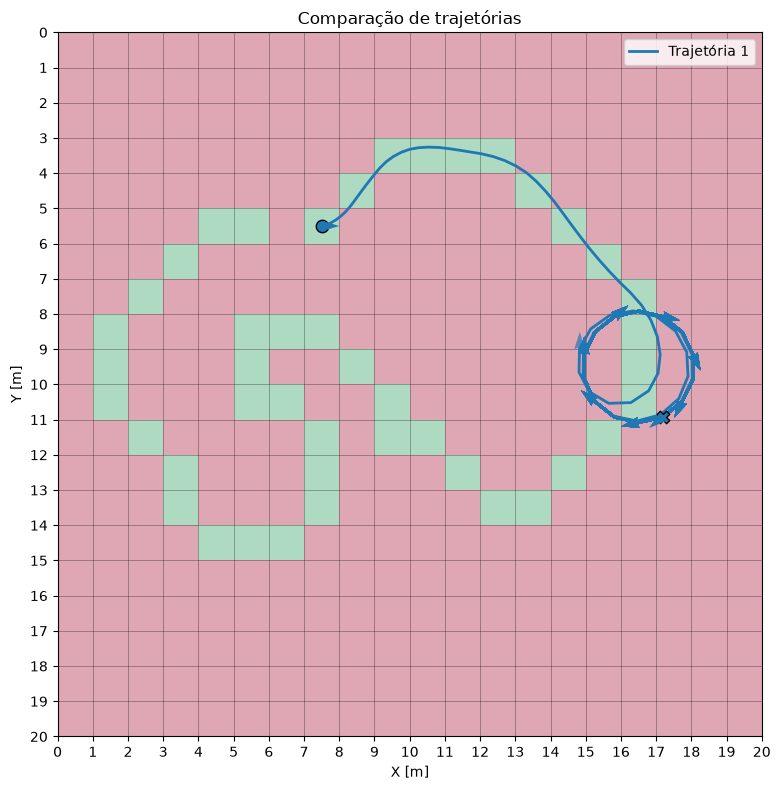

In [5]:

height = 20
width = 20

# grid = build_cost_map(width, height)
grid = race

inicio = (5 * escale, 7 * escale)
destino = (5 * escale, 5 * escale)

caminho = dijkstra(grid, inicio, destino)

CELL_WIDTH = 1 # 10 cm

DT = 0.5

estado_inicial = Vehicle_state(
    X=(inicio[1] + 0.5) * CELL_WIDTH,
    Y=(inicio[0] + 0.5) * CELL_WIDTH,
    psi=(math.pi / 4) * 0,
    vx=0,
    omega=0.0
)

torques_referencia, estados_calculados = generate_torque_reference(
    caminho=caminho,
    estado_inicial=estado_inicial,
    params=car_params,
    cell_width=CELL_WIDTH,
    dt=DT,
    v_ref=0.3
)

print("Número de amostras:", len(torques_referencia))

plot_trajectory(
    paths=[estados_calculados],
    grid=grid,
    CELL_WIDTH=CELL_WIDTH
)

In [6]:
# # Torques aplicados no passo anterior
# T_prev = WeelTork(
#     Fl=0,
#     Fr=0,
#     Rl=0,
#     Rr=0,
# )

# estados_calculados_otimizado = [estado_inicial]
# torques_otimizado = [T_prev]

# t = 0

# for i, torque in enumerate(torques_referencia):

#     print(f"\r{(i * 100 / len(torques_referencia)):.2f}%", end="", flush=True)

#     Fx, Mz, Ploss = model(torque, car_params)
    
#     # Referências do controlador
#     ref = Reference(
#         Fx=Fx,
#         Mz=Mz
#     )

#     problem = TorqueDistributionProblem(
#         params=car_params,
#         ref=ref,
#         T_prev=torques_otimizado[-1]
#     )

#     result = minimize(
#         problem,
#         algorithm,
#         termination=("n_gen", 100),
#         seed=1,
#         verbose=False
#     )
    
#     # Escolhe uma das soluções de compromisso como referencia
#     T_result = result.X[-1]

#     T_opt = WeelTork(
#         Fl=T_result[0],
#         Fr=T_result[1],
#         Rl=T_result[2],
#         Rr=T_result[3],
#     )
#     torques_otimizado.append(T_opt)

#     last_state = estados_calculados_otimizado[-1]

#     next_state = vehicle_dynamics(
#         T_opt,
#         last_state,
#         car_params,
#         DT
#     )

#     estados_calculados_otimizado.append(next_state)

#     t += DT

# plot_trajectory(
#     estados_calculados_otimizado,
#     grid,
#     caminho,
#     CELL_WIDTH
# )




In [7]:
celula_atual = inicio

T_prev = WeelTork(
    Fl=0,
    Fr=0,
    Rl=0,
    Rr=0,
)

estados_calculados_online = [estado_inicial]
torques_otimizado_online = [T_prev]

t = 0

# Definindo algoritmo e quantidade de individuos da população

algorithm = NSGA2(
    pop_size=100,
    eliminate_duplicates=True
)

caminho_dijkstra_reverso = dijkstra_reverso(grid, destino)

while celula_atual != destino:

    proxima_celula = caminho_dijkstra_reverso[celula_atual]

    if proxima_celula is None:
        print("Não foi encontrado caminho até o destino!")
        break
    
    # Calcula uma lista de torques necessarios para chegar na proxima celula
    torques_referencia, estados_calculados = generate_torque_reference(
        caminho=[celula_atual, proxima_celula],
        estado_inicial=estados_calculados_online[-1],
        params=car_params,
        cell_width=CELL_WIDTH,
        dt=DT,
        v_ref=0.3
    )

    # Utiliza apenas a primeira referencia (O carrinho pode mudar de celula após aplicar o torque, portanto aplicamos apenas o primeiro)
    Fx, Mz, Ploss = model(torques_referencia[0], car_params)
    
    # Referências do controlador
    ref = Reference(
        Fx=Fx,
        Mz=Mz
    )
    # Cria o problema com esse torque de referencia para cada roda
    problem = TorqueDistributionProblem(
        params=car_params,
        ref=ref,
        T_prev=torques_otimizado_online[-1]
    )

    # Minimiza para encontrar o torque real
    result = minimize(
        problem,
        algorithm,
        termination=("n_gen", 10),
        seed=1,
        verbose=False
    )
    
    # Escolhe uma das soluções de compromisso como referencia
    T_result = result.X[-1]

    T_opt = WeelTork(
        Fl=T_result[0],
        Fr=T_result[1],
        Rl=T_result[2],
        Rr=T_result[3],
    )
    torques_otimizado_online.append(T_opt)

    next_state = vehicle_dynamics(
        T_opt,
        estados_calculados_online[-1],
        car_params,
        DT
    )

    celula_atual = (int(next_state.X // CELL_WIDTH), int(next_state.Y // CELL_WIDTH))

    estados_calculados_online.append(next_state)

    t += DT

plot_trajectory(
    grid = grid,
    CELL_WIDTH = CELL_WIDTH,
    paths = [estados_calculados_online],
)


KeyError: (-1, 4)

In [ ]:
# pareto_F = result.F
# plot_pareto(pareto_F)


# Fx_opt, Mz_opt, Ploss_opt = model(T_opt, car_params)

# print("Torques ótimos [N.m]:", T_opt)
# print("Fx [N]:", Fx_opt)
# print("Mz [N.m]:", Mz_opt)
# print("Perdas [W]:", Ploss_opt)

# print("x" * 64)